# Лабораторная работа №2 — Классификация

Данные: Titanic Dataset. Целевая переменная: `Survived` (1 — выжил, 0 — не выжил).

Основная метрика: F1-score для класса 1. Требование задания: **F1 > 0.70** на единой тестовой выборке.

## 1. Подготовка окружения

Подключаем библиотеки и задаём `RANDOM_STATE`, который будем использовать при разбиении данных и обучении моделей.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (9, 5)

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")
print(f"Matplotlib: {plt.matplotlib.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"random_state: {RANDOM_STATE}")

Python: 3.13.5
NumPy: 2.1.3
pandas: 2.2.3
Matplotlib: 3.10.0
scikit-learn: 1.6.1
random_state: 42


## 2. Загрузка данных

Датасет: [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset).

Целевая переменная: `Survived` (1 — выжил, 0 — не выжил).

In [2]:
from pathlib import Path
from IPython.display import display

data_path = Path("data/Titanic-Dataset.csv")
if not data_path.exists():
    data_path = Path("classification/data/Titanic-Dataset.csv")

data = pd.read_csv(data_path)

print(f"Размер таблицы: {data.shape[0]} строк, {data.shape[1]} столбцов")
print("Столбцы:", ", ".join(data.columns))
display(data.head())

Размер таблицы: 891 строк, 12 столбцов
Столбцы: PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Типы данных, пропуски и дубликаты

In [3]:
summary = pd.DataFrame({
    "Тип": data.dtypes.astype(str),
    "Пропуски": data.isna().sum(),
    "Пропуски, %": (data.isna().mean() * 100).round(2),
})

display(summary)
print(f"Полных дубликатов: {data.duplicated().sum()}")

,Тип,Пропуски,"Пропуски, %"
PassengerId,int64,0,0.00
Survived,int64,0,0.00
Pclass,int64,0,0.00
Name,object,0,0.00
Sex,object,0,0.00
Age,float64,177,19.87
SibSp,int64,0,0.00
Parch,int64,0,0.00
Ticket,object,0,0.00
Fare,float64,0,0.00


Полных дубликатов: 0


Пропуски есть в `Age`, `Cabin` и `Embarked`; больше всего — в `Cabin` (77.10%). Полных дубликатов нет. Обработку пропусков выполним после разделения данных, обучая преобразования только на train.

## 4. Разделение на train и test

Выделяем 20% данных для финальной проверки. Стратификация сохраняет соотношение классов, `random_state=42` фиксирует разбиение. Целевой столбец `Survived` исключаем из признаков.

In [4]:
from sklearn.model_selection import train_test_split

X = data.drop(columns="Survived")
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

class_shares = pd.DataFrame({
    "train, %": y_train.value_counts(normalize=True) * 100,
    "test, %": y_test.value_counts(normalize=True) * 100,
}).sort_index().round(2)
class_shares.index.name = "Survived"

display(class_shares)

Train: (712, 11) | Test: (179, 11)


,"train, %","test, %"
Survived,,
0,61.66,61.45
1,38.34,38.55


Соотношение классов в train и test практически одинаковое. Дальнейший анализ, подготовку признаков и выбор параметров выполняем на train. Test используем только для финальной оценки всех моделей.

## 5. Доля выживших по полу и классу билета

Анализируем только обучающую выборку.

,Пассажиров,"Выжили, %"
Sex,,
female,253,74.31
male,459,18.52


,Пассажиров,"Выжили, %"
Pclass,,
1,171,64.91
2,150,44.67
3,391,24.30


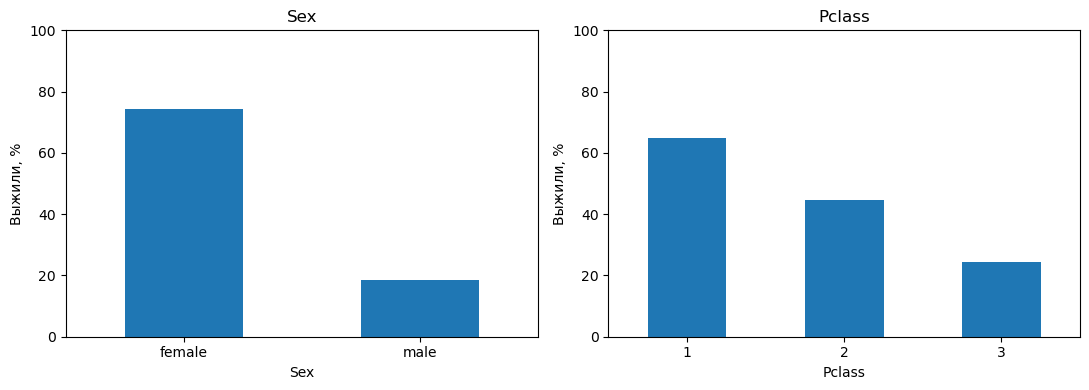

In [5]:
train_data = X_train.assign(Survived=y_train)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for feature, ax in zip(["Sex", "Pclass"], axes):
    stats = train_data.groupby(feature)["Survived"].agg(["count", "mean"])
    stats.columns = ["Пассажиров", "Выжили, %"]
    stats["Выжили, %"] = (stats["Выжили, %"] * 100).round(2)
    display(stats)

    stats["Выжили, %"].plot.bar(ax=ax, rot=0)
    ax.set_title(feature)
    ax.set_ylabel("Выжили, %")
    ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

В обучающей выборке доля выживших выше среди женщин и пассажиров первого класса. `Sex` и `Pclass` могут быть полезны для предсказания. Эти групповые различия сами по себе не доказывают причинную связь.

## 6. Возраст и стоимость билета

Сравниваем распределения на train с отдельной нормировкой для каждого класса. Стоимость билета показываем в масштабе `log(1 + Fare)`; исходные данные не изменяем.

Age         Fare       
         count median count median
Survived                          
0          342  28.25   439   10.5
1          233  29.00   273   26.0

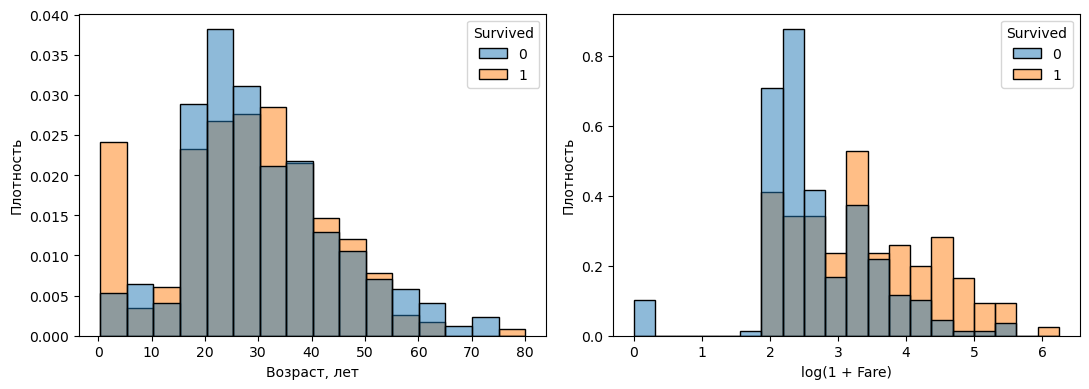

In [6]:
import seaborn as sns

display(
    train_data.groupby("Survived")[["Age", "Fare"]]
    .agg(["count", "median"]).round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(
    data=train_data, x="Age", hue="Survived", bins=16,
    stat="density", common_norm=False, ax=axes[0],
)
sns.histplot(
    data=train_data.assign(log_fare=np.log1p(train_data["Fare"])),
    x="log_fare", hue="Survived", bins=20,
    stat="density", common_norm=False, ax=axes[1],
)

axes[0].set(xlabel="Возраст, лет", ylabel="Плотность")
axes[1].set(xlabel="log(1 + Fare)", ylabel="Плотность")
plt.tight_layout()
plt.show()

Распределения возраста двух классов сильно пересекаются. У выживших медианная стоимость билета выше. При дальнейшем анализе нужно учитывать связь стоимости билета с классом обслуживания.

## 7. Признаки и предобработка

Для числовых признаков используем заполнение медианой, для категориальных — наиболее частым значением и One-Hot Encoding. Для SVM и KNN дополнительно масштабируем числовые признаки.

В начальной схеме не используем `PassengerId`, `Name`, `Ticket` и `Cabin`. Информативность факта заполнения `Cabin` исследуем отдельно. Все параметры преобразований будут обучаться внутри Pipeline только на обучающих данных.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Pclass", "Sex", "Embarked"]

def make_preprocessor(scale=False, use_cabin=True):
    selected_numeric = [
        f for f in numeric_features if use_cabin or f != "HasCabin"
    ]
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))

    return ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), selected_numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore", sparse_output=False,
            )),
        ]), categorical_features),
    ], remainder="drop", verbose_feature_names_out=False)

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)
print("Исключены:", X_train.columns.difference(
    numeric_features + categorical_features
).tolist())
print("Схема предобработки задана; обучение ещё не выполнялось.")

Числовые признаки: ['Age', 'SibSp', 'Parch', 'Fare']
Категориальные признаки: ['Pclass', 'Sex', 'Embarked']
Исключены: ['Cabin', 'Name', 'PassengerId', 'Ticket']
Схема предобработки задана; обучение ещё не выполнялось.


## 8. Информативность Cabin и корреляции

Проверяем наличие `Cabin` отдельно и внутри классов билета. Корреляции считаем только на train; номинальные категории представляем индикаторами. Для `Age` используются только пары без пропусков.

,n,survival_rate
HasCabin,,
0,552,0.292
1,160,0.700


n  survival_rate
Pclass HasCabin                    
1      0          35          0.457
       1         136          0.699
2      0         135          0.407
       1          15          0.800
3      0         382          0.236
       1           9          0.556

,r с Survived
Sex_male,-0.549
HasCabin,0.351
Pclass,-0.348
Fare,0.275
Embarked_S,-0.187
Age,-0.084
Parch,0.084
Embarked_Unknown,0.067
Embarked_Q,0.032
SibSp,-0.026


r(HasCabin, Pclass): -0.713


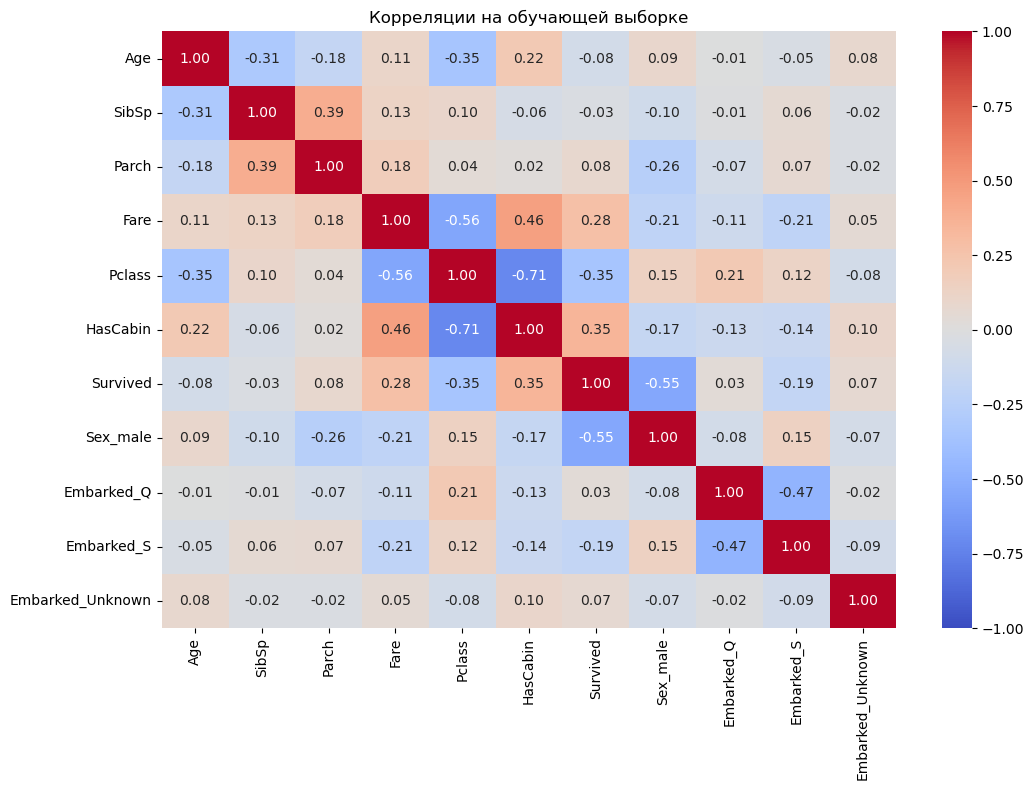

In [8]:
eda = train_data.assign(
    HasCabin=train_data["Cabin"].notna().astype(int)
)

display(
    eda.groupby("HasCabin")["Survived"]
    .agg(n="size", survival_rate="mean").round(3)
)
display(
    eda.groupby(["Pclass", "HasCabin"])["Survived"]
    .agg(n="size", survival_rate="mean").round(3)
)

corr_data = eda[[
    "Age", "SibSp", "Parch", "Fare", "Pclass",
    "Sex", "Embarked", "HasCabin", "Survived",
]].copy()
corr_data["Embarked"] = corr_data["Embarked"].fillna("Unknown")
corr_data = pd.get_dummies(
    corr_data, columns=["Sex", "Embarked"], drop_first=True, dtype=int
)
corr = corr_data.corr()

display(
    corr["Survived"].drop("Survived")
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .round(3).to_frame("r с Survived")
)
print("r(HasCabin, Pclass):", round(corr.loc["HasCabin", "Pclass"], 3))

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, center=0,
)
plt.title("Корреляции на обучающей выборке")
plt.tight_layout()
plt.show()

Наличие `Cabin` связано и с выживанием (r = 0.351), и с классом билета (r = -0.713). Различия в выживаемости сохраняются внутри каждого класса, но группы с известной каютой во втором и третьем классах малы (15 и 9 пассажиров). `HasCabin` — кандидат на дополнительный признак; его пользу сверх `Pclass` проверим по кросс-валидации на train.

Наибольшие по модулю корреляции с таргетом имеют пол, наличие каюты и класс билета. Корреляция Пирсона описывает линейную связь; её низкое значение не исключает нелинейных зависимостей и взаимодействий. Удалять признаки только по этой матрице не будем.

## 9. Добавление HasCabin и проверка предобработки

`HasCabin` равен 1, если каюта известна, и 0 в противном случае. Проверяем предобработку на train. Для моделей и кросс-валидации будем создавать новые экземпляры преобразований.

In [9]:
X_train = X_train.assign(
    HasCabin=X_train["Cabin"].notna().astype(int)
)
X_test = X_test.assign(
    HasCabin=X_test["Cabin"].notna().astype(int)
)

numeric_features = ["Age", "SibSp", "Parch", "Fare", "HasCabin"]

preview_preprocessor = make_preprocessor()
preview = pd.DataFrame(
    preview_preprocessor.fit_transform(X_train),
    columns=preview_preprocessor.get_feature_names_out(),
    index=X_train.index,
)

print("Train после обработки:", preview.shape)
print("Пропусков после обработки:", preview.isna().sum().sum())
display(preview.head())

Train после обработки: (712, 13)
Пропусков после обработки: 0


,Age,SibSp,Parch,Fare,HasCabin,Pclass_1,Pclass_2,Pclass_3,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
692,28.5,0.0,0.0,56.4958,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
481,28.5,0.0,0.0,0.0000,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
527,28.5,0.0,0.0,221.7792,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
855,18.0,0.0,1.0,9.3500,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
801,31.0,1.0,1.0,26.2500,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


## 10. Dummy baseline

Всегда предсказываем наиболее частый класс. Получаем OOF-прогнозы на пяти стратифицированных фолдах train и считаем метрики для класса `Survived = 1`. Test не используем.

,Accuracy,Precision,Recall,F1
Dummy,0.617,0.0,0.0,0.0


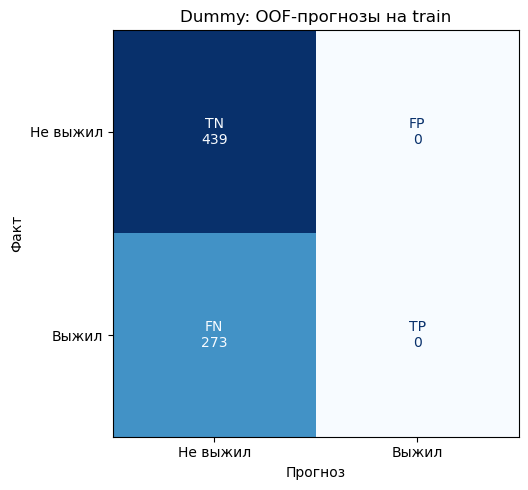

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def classification_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

baseline = DummyClassifier(strategy="most_frequent")
cv_predictions = {
    "Dummy": cross_val_predict(baseline, X_train, y_train, cv=cv)
}
cv_scores = {
    "Dummy": classification_metrics(y_train, cv_predictions["Dummy"])
}

display(pd.DataFrame.from_dict(cv_scores, orient="index").round(3))

disp = ConfusionMatrixDisplay.from_predictions(
    y_train, cv_predictions["Dummy"],
    labels=[0, 1], display_labels=["Не выжил", "Выжил"],
    cmap="Blues", colorbar=False,
)
for name, text in zip(["TN", "FP", "FN", "TP"], disp.text_.ravel()):
    text.set_text(f"{name}\n{text.get_text()}")

disp.ax_.set(
    xlabel="Прогноз", ylabel="Факт",
    title="Dummy: OOF-прогнозы на train",
)
plt.tight_layout()
plt.show()

Dummy предсказывает 0 для всех пассажиров: Accuracy ≈ 0.617, но Precision, Recall и F1 для выживших равны 0. Все 273 выживших в train пропущены. Это показывает, почему одной Accuracy недостаточно.

Положительный класс — выжил (`Survived = 1`). В матрице: TN и FP в верхней строке, FN и TP — в нижней.

## 11. Дерево решений и проверка HasCabin

Сравниваем дерево с `HasCabin` и без него на одинаковых фолдах train. Используем начальное дерево без ограничения глубины. Для дальнейшего сравнения моделей сохраняем вариант с большим OOF F1; test не используем.

,Accuracy,Precision,Recall,F1
Без HasCabin,0.77,0.706,0.685,0.695
С HasCabin,0.77,0.703,0.692,0.697


Выбранный вариант: С HasCabin
F1 на train: 0.981
F1 OOF: 0.697


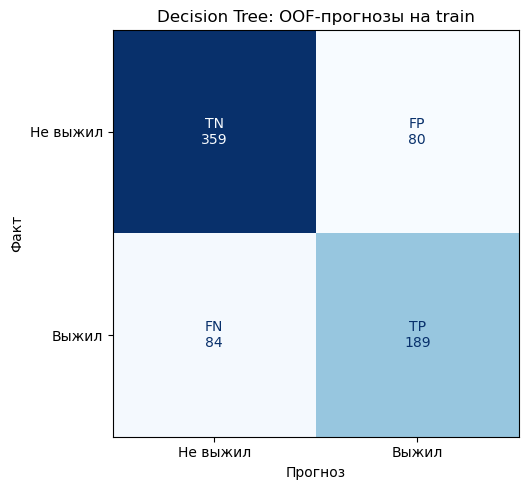

In [11]:
from sklearn.tree import DecisionTreeClassifier

tree_variants = {}
tree_oof = {}
tree_scores = {}

for name, use_cabin in [("Без HasCabin", False), ("С HasCabin", True)]:
    tree_variants[name] = Pipeline([
        ("preprocessor", make_preprocessor(use_cabin=use_cabin)),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ])
    tree_oof[name] = cross_val_predict(
        tree_variants[name], X_train, y_train, cv=cv
    )
    tree_scores[name] = classification_metrics(y_train, tree_oof[name])

display(pd.DataFrame.from_dict(tree_scores, orient="index").round(3))

best_tree_variant = max(tree_scores, key=lambda name: tree_scores[name]["F1"])
tree_model = tree_variants[best_tree_variant]
tree_model.fit(X_train, y_train)

models = {"Decision Tree": tree_model}
cv_predictions["Decision Tree"] = tree_oof[best_tree_variant]
cv_scores["Decision Tree"] = tree_scores[best_tree_variant]

print("Выбранный вариант:", best_tree_variant)
print("F1 на train:", round(f1_score(y_train, tree_model.predict(X_train)), 3))
print("F1 OOF:", round(cv_scores["Decision Tree"]["F1"], 3))

disp = ConfusionMatrixDisplay.from_predictions(
    y_train, cv_predictions["Decision Tree"],
    labels=[0, 1], display_labels=["Не выжил", "Выжил"],
    cmap="Blues", colorbar=False,
)
for name, text in zip(["TN", "FP", "FN", "TP"], disp.text_.ravel()):
    text.set_text(f"{name}\n{text.get_text()}")

disp.ax_.set(
    xlabel="Прогноз", ylabel="Факт",
    title="Decision Tree: OOF-прогнозы на train",
)
plt.tight_layout()
plt.show()

У дерева без ограничения глубины F1 на train = 0.981, а OOF F1 = 0.697: есть признаки переобучения. С `HasCabin` OOF F1 вырос с 0.695 до 0.697; разница мала и не доказывает устойчивого улучшения. Для следующего шага сохраняем этот вариант и проверим ограничение сложности дерева на train. Требование F1 > 0.70 на единой тестовой выборке пока не проверялось.

## 12. Ограничение сложности дерева

Подбираем `max_depth` и `min_samples_leaf` по среднему F1 на пяти фолдах train. OOF после выбора параметров на тех же фолдах может давать оптимистичную оценку; test оставляем для финальной проверки.

In [12]:
from sklearn.model_selection import GridSearchCV

tree_before_tuning = cv_scores["Decision Tree"].copy()

tree_search = GridSearchCV(
    estimator=tree_model,
    param_grid={
        "model__max_depth": [3, 4, 5, 6, 8, None],
        "model__min_samples_leaf": [1, 3, 5, 10],
    },
    scoring="f1",
    cv=cv,
    n_jobs=1,
)
tree_search.fit(X_train, y_train)

tree_model = tree_search.best_estimator_
models["Decision Tree"] = tree_model
cv_predictions["Decision Tree"] = cross_val_predict(
    tree_model, X_train, y_train, cv=cv
)
cv_scores["Decision Tree"] = classification_metrics(
    y_train, cv_predictions["Decision Tree"]
)

print("Лучшие параметры:", tree_search.best_params_)
print("Средний CV F1:", round(tree_search.best_score_, 3))
print("F1 на train:", round(f1_score(y_train, tree_model.predict(X_train)), 3))

display(pd.DataFrame.from_dict({
    "До подбора": tree_before_tuning,
    "После подбора": cv_scores["Decision Tree"],
}, orient="index").round(3))

Лучшие параметры: {'model__max_depth': 6, 'model__min_samples_leaf': 5}
Средний CV F1: 0.736
F1 на train: 0.822


,Accuracy,Precision,Recall,F1
До подбора,0.77,0.703,0.692,0.697
После подбора,0.81,0.788,0.692,0.737


Лучшие параметры в проверенной сетке: `max_depth=6`, `min_samples_leaf=5`. OOF F1 вырос с 0.697 до 0.737, а F1 на train снизился с 0.981 до 0.822: разрыв уменьшился. Precision вырос с 0.703 до 0.788 при прежнем Recall 0.692. Итоговую оценку качества получим на test после сравнения моделей.

## 13. Важность признаков дерева

Используем снижение неоднородности в разбиениях обученного дерева. Важности One-Hot столбцов суммируем по исходным признакам. Сумма важностей равна 1; это не оценка причинного влияния на выживание.

,Важность
Sex,0.508
Age,0.133
Pclass,0.132
Fare,0.124
HasCabin,0.065
Embarked,0.036
SibSp,0.002
Parch,0.001


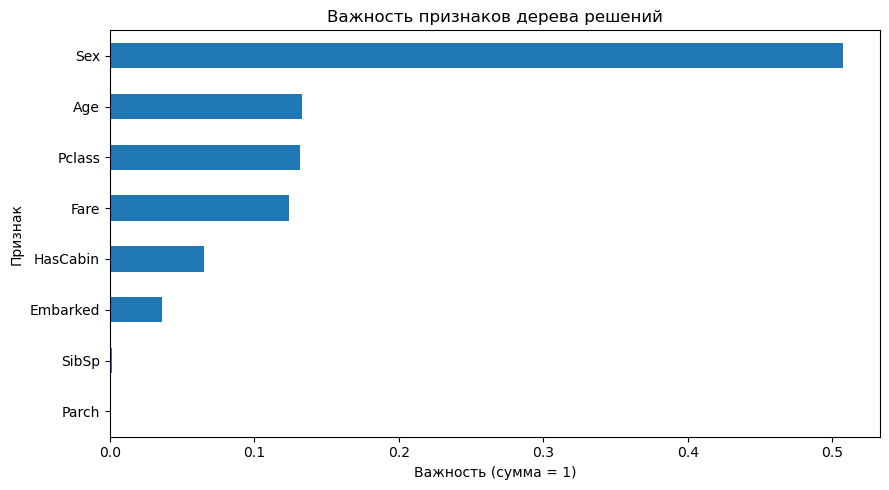

In [13]:
feature_names = tree_model.named_steps["preprocessor"].get_feature_names_out()

tree_importance = pd.Series(
    tree_model.named_steps["model"].feature_importances_,
    index=feature_names,
)
tree_grouped_importance = (
    tree_importance.groupby(lambda name: name.split("_")[0])
    .sum().sort_values(ascending=False)
)

display(tree_grouped_importance.to_frame("Важность").round(3))

tree_grouped_importance.sort_values().plot.barh(figsize=(9, 5))
plt.xlabel("Важность (сумма = 1)")
plt.ylabel("Признак")
plt.title("Важность признаков дерева решений")
plt.tight_layout()
plt.show()

Наибольшая важность у пола (0.508), затем идут возраст (0.133), класс билета (0.132) и стоимость билета (0.124). Пол и класс были связаны с выживанием и в EDA. Несмотря на слабую корреляцию возраста с таргетом, дерево использует его в нелинейных разбиениях. `HasCabin` имеет важность 0.065, но это не доказывает устойчивого прироста качества: ранее разница OOF F1 с ним и без него была мала. При коррелирующих признаках важность может распределяться между ними; это не причинный эффект.

## 14. Случайный лес

Обучаем Random Forest из 300 деревьев. Предобработка обучается внутри каждого фолда; масштабирование не используем. Оцениваем на тех же фолдах train и сравниваем с Dummy и деревом решений.

F1 на train: 0.981
F1 OOF: 0.74


,Accuracy,Precision,Recall,F1
Dummy,0.617,0.000,0.000,0.000
Decision Tree,0.810,0.788,0.692,0.737
Random Forest,0.805,0.756,0.725,0.740


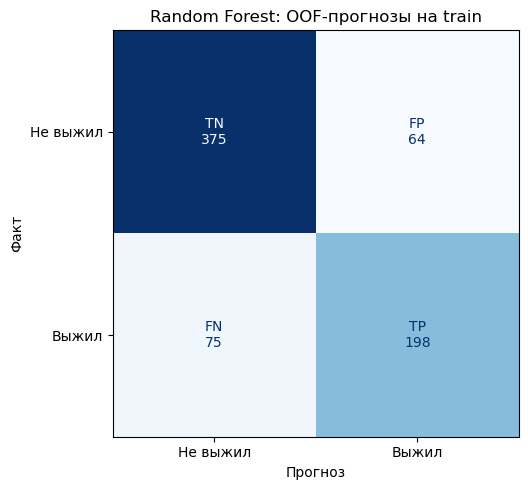

In [14]:
from sklearn.ensemble import RandomForestClassifier

forest_model = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )),
])

cv_predictions["Random Forest"] = cross_val_predict(
    forest_model, X_train, y_train, cv=cv
)
cv_scores["Random Forest"] = classification_metrics(
    y_train, cv_predictions["Random Forest"]
)

forest_model.fit(X_train, y_train)
models["Random Forest"] = forest_model

print("F1 на train:", round(f1_score(y_train, forest_model.predict(X_train)), 3))
print("F1 OOF:", round(cv_scores["Random Forest"]["F1"], 3))
display(pd.DataFrame.from_dict(cv_scores, orient="index").round(3))

disp = ConfusionMatrixDisplay.from_predictions(
    y_train, cv_predictions["Random Forest"],
    labels=[0, 1], display_labels=["Не выжил", "Выжил"],
    cmap="Blues", colorbar=False,
)
for name, text in zip(["TN", "FP", "FN", "TP"], disp.text_.ravel()):
    text.set_text(f"{name}\n{text.get_text()}")

disp.ax_.set(
    xlabel="Прогноз", ylabel="Факт",
    title="Random Forest: OOF-прогнозы на train",
)
plt.tight_layout()
plt.show()

Random Forest получил OOF F1 = 0.740 против 0.737 у настроенного дерева. Разница мала. Recall вырос с 0.692 до 0.725, а Precision снизился с 0.788 до 0.756: лес нашёл больше выживших, но чаще предсказывал выживание для погибших. F1 на train = 0.981, поэтому разрыв с OOF остаётся большим. Test не использовался.

## 15. Настройка случайного леса

Проверяем 18 сочетаний `max_depth`, `min_samples_leaf` и `max_features` по среднему F1 на пяти фолдах train. Число деревьев оставляем равным 300. OOF после подбора на тех же фолдах может быть оптимистичным; test не используем.

In [15]:
forest_before_tuning = cv_scores["Random Forest"].copy()

forest_search = GridSearchCV(
    estimator=forest_model,
    param_grid={
        "model__max_depth": [4, 6, None],
        "model__min_samples_leaf": [1, 3, 5],
        "model__max_features": ["sqrt", 1.0],
    },
    scoring="f1",
    cv=cv,
    n_jobs=1,
)
forest_search.fit(X_train, y_train)

forest_model = forest_search.best_estimator_
models["Random Forest"] = forest_model
cv_predictions["Random Forest"] = cross_val_predict(
    forest_model, X_train, y_train, cv=cv
)
cv_scores["Random Forest"] = classification_metrics(
    y_train, cv_predictions["Random Forest"]
)

print("Лучшие параметры:", forest_search.best_params_)
print("Средний CV F1:", round(forest_search.best_score_, 3))
print("F1 на train:", round(f1_score(y_train, forest_model.predict(X_train)), 3))

display(pd.DataFrame.from_dict({
    "Лес до подбора": forest_before_tuning,
    "Лес после подбора": cv_scores["Random Forest"],
    "Дерево после подбора": cv_scores["Decision Tree"],
}, orient="index").round(3))

Лучшие параметры: {'model__max_depth': 6, 'model__max_features': 1.0, 'model__min_samples_leaf': 1}
Средний CV F1: 0.752
F1 на train: 0.875


,Accuracy,Precision,Recall,F1
Лес до подбора,0.805,0.756,0.725,0.740
Лес после подбора,0.822,0.807,0.703,0.751
Дерево после подбора,0.810,0.788,0.692,0.737


Лучшие параметры в проверенной сетке: `max_depth=6`, `min_samples_leaf=1`, `max_features=1.0` (при разбиении рассматриваются все признаки). OOF F1 вырос с 0.740 до 0.751, а F1 на train снизился с 0.981 до 0.875: разрыв уменьшился. Настроенное дерево имеет OOF F1 = 0.737. Это результаты выбора на train; окончательное сравнение выполним на test.

## 16. Сравнение важности признаков дерева и леса

Суммируем важности One-Hot столбцов по исходным признакам. В каждом столбце сумма равна 1. Сравниваем настроенные модели, обученные на train.

,Дерево,Лес
Sex,0.508,0.443
Age,0.133,0.165
Fare,0.124,0.156
Pclass,0.132,0.115
HasCabin,0.065,0.054
Embarked,0.036,0.032
SibSp,0.002,0.023
Parch,0.001,0.012


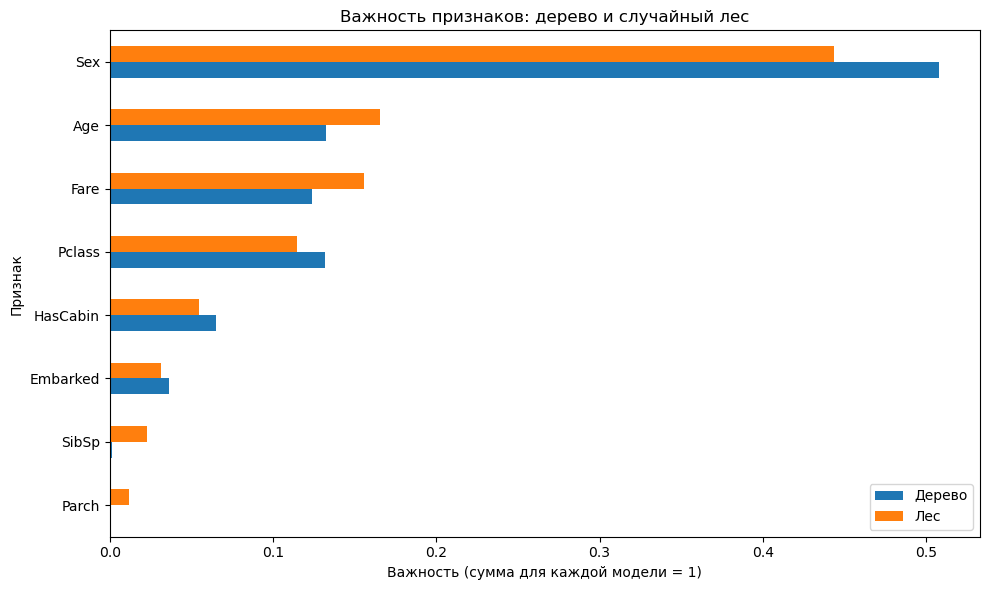

In [16]:
forest_feature_names = (
    forest_model.named_steps["preprocessor"].get_feature_names_out()
)
forest_importance = pd.Series(
    forest_model.named_steps["model"].feature_importances_,
    index=forest_feature_names,
)
forest_grouped_importance = (
    forest_importance.groupby(lambda name: name.split("_")[0]).sum()
)

importance_comparison = pd.DataFrame({
    "Дерево": tree_grouped_importance,
    "Лес": forest_grouped_importance,
}).fillna(0).sort_values("Лес", ascending=False)

display(importance_comparison.round(3))

importance_comparison.iloc[::-1].plot.barh(figsize=(10, 6))
plt.xlabel("Важность (сумма для каждой модели = 1)")
plt.ylabel("Признак")
plt.title("Важность признаков: дерево и случайный лес")
plt.tight_layout()
plt.show()

В обеих моделях лидирует пол пассажира; далее идут возраст, стоимость билета и класс. У леса важность пола ниже (0.443 против 0.508), а возраста и стоимости билета — выше. Это согласуется с EDA по полу и классу и показывает, что слабая линейная корреляция возраста не исключает его использования деревьями. `HasCabin` имеет ненулевую важность в обеих моделях; независимую пользу нельзя установить только по этому графику.

## 17. Градиентный бустинг

Обучаем 100 деревьев глубиной до 3 со скоростью обучения 0.1. Используем тот же набор признаков и те же фолды train. Параметры предобработки обучаются внутри каждого фолда; test не используем.

F1 на train: 0.877
F1 OOF: 0.761


,Accuracy,Precision,Recall,F1
Dummy,0.617,0.000,0.000,0.000
Decision Tree,0.810,0.788,0.692,0.737
Random Forest,0.822,0.807,0.703,0.751
Gradient Boosting,0.826,0.804,0.722,0.761


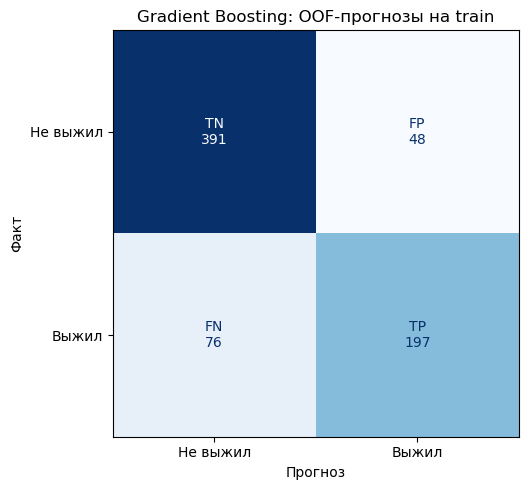

In [17]:
from sklearn.ensemble import GradientBoostingClassifier

boosting_model = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE,
    )),
])

cv_predictions["Gradient Boosting"] = cross_val_predict(
    boosting_model, X_train, y_train, cv=cv
)
cv_scores["Gradient Boosting"] = classification_metrics(
    y_train, cv_predictions["Gradient Boosting"]
)

boosting_model.fit(X_train, y_train)
models["Gradient Boosting"] = boosting_model

print("F1 на train:", round(f1_score(y_train, boosting_model.predict(X_train)), 3))
print("F1 OOF:", round(cv_scores["Gradient Boosting"]["F1"], 3))
display(pd.DataFrame.from_dict(cv_scores, orient="index").round(3))

disp = ConfusionMatrixDisplay.from_predictions(
    y_train, cv_predictions["Gradient Boosting"],
    labels=[0, 1], display_labels=["Не выжил", "Выжил"],
    cmap="Blues", colorbar=False,
)
for name, text in zip(["TN", "FP", "FN", "TP"], disp.text_.ravel()):
    text.set_text(f"{name}\n{text.get_text()}")

disp.ax_.set(
    xlabel="Прогноз", ylabel="Факт",
    title="Gradient Boosting: OOF-прогнозы на train",
)
plt.tight_layout()
plt.show()

Gradient Boosting получил OOF F1 = 0.761 против 0.751 у настроенного леса и 0.737 у дерева. Precision = 0.804, Recall = 0.722. F1 на train = 0.877: разрыв с OOF остаётся. Это стартовые параметры бустинга; test не использовался.

## 18. Важность признаков трёх моделей

Сравниваем дерево, настроенный лес и бустинг. Важности One-Hot столбцов суммируем по исходным признакам; сумма для каждой модели равна 1.

,Дерево,Лес,Бустинг
Sex,0.508,0.443,0.459
Fare,0.124,0.156,0.167
Age,0.133,0.165,0.146
Pclass,0.132,0.115,0.123
HasCabin,0.065,0.054,0.056
SibSp,0.002,0.023,0.025
Embarked,0.036,0.032,0.023
Parch,0.001,0.012,0.001


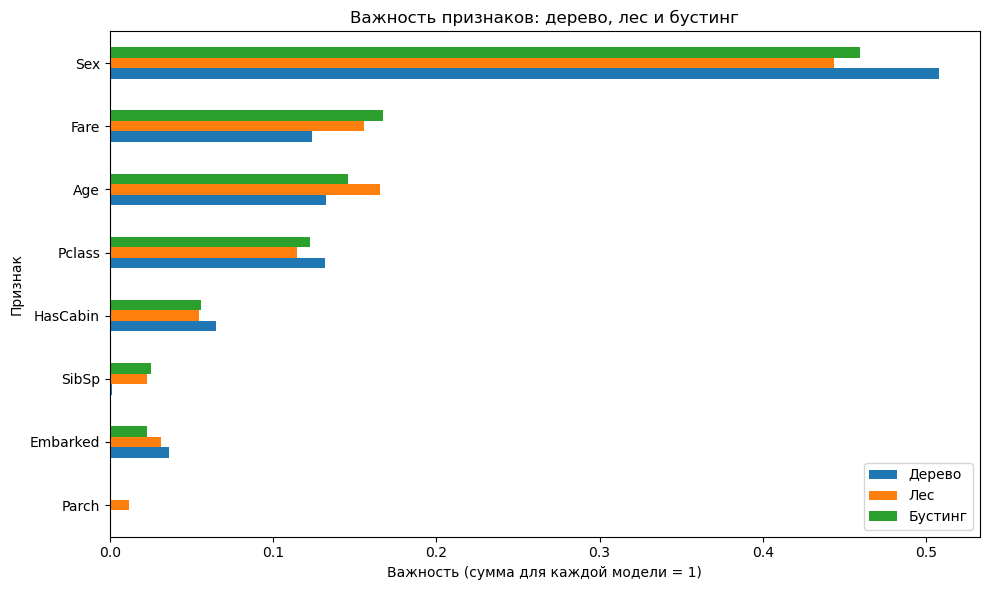

In [18]:
boosting_feature_names = (
    boosting_model.named_steps["preprocessor"].get_feature_names_out()
)
boosting_importance = pd.Series(
    boosting_model.named_steps["model"].feature_importances_,
    index=boosting_feature_names,
)
boosting_grouped_importance = (
    boosting_importance.groupby(lambda name: name.split("_")[0]).sum()
)

importance_comparison = pd.DataFrame({
    "Дерево": tree_grouped_importance,
    "Лес": forest_grouped_importance,
    "Бустинг": boosting_grouped_importance,
}).fillna(0).sort_values("Бустинг", ascending=False)

display(importance_comparison.round(3))

importance_comparison.iloc[::-1].plot.barh(figsize=(10, 6))
plt.xlabel("Важность (сумма для каждой модели = 1)")
plt.ylabel("Признак")
plt.title("Важность признаков: дерево, лес и бустинг")
plt.tight_layout()
plt.show()

Все три модели выделяют пол, стоимость билета, возраст и класс. Это согласуется с EDA по полу, классу и стоимости билета. У бустинга наибольшая важность пола (0.459), затем стоимости билета (0.167) и возраста (0.146). Важность `HasCabin` близка у всех моделей (0.054–0.065). Согласие моделей показывает устойчивость наблюдаемой картины в этом разбиении, но не доказывает причинность или дополнительный прирост качества от каждого признака.

## 19. Метод опорных векторов

Используем SVM с RBF-ядром, `C=1` и `gamma="scale"`. Числовые признаки масштабируем внутри Pipeline: RBF-ядро зависит от расстояний. Оцениваем на прежних пяти фолдах train; test не используем.

F1 на train: 0.787
F1 OOF: 0.739


,Accuracy,Precision,Recall,F1
Dummy,0.617,0.000,0.000,0.000
Decision Tree,0.810,0.788,0.692,0.737
Random Forest,0.822,0.807,0.703,0.751
Gradient Boosting,0.826,0.804,0.722,0.761
SVM,0.808,0.770,0.711,0.739


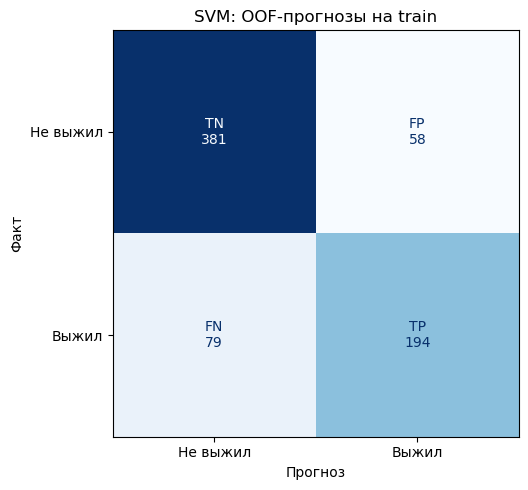

In [19]:
from sklearn.svm import SVC

svm_model = Pipeline([
    ("preprocessor", make_preprocessor(scale=True)),
    ("model", SVC(kernel="rbf", C=1.0, gamma="scale")),
])

cv_predictions["SVM"] = cross_val_predict(
    svm_model, X_train, y_train, cv=cv
)
cv_scores["SVM"] = classification_metrics(
    y_train, cv_predictions["SVM"]
)

svm_model.fit(X_train, y_train)
models["SVM"] = svm_model

print("F1 на train:", round(f1_score(y_train, svm_model.predict(X_train)), 3))
print("F1 OOF:", round(cv_scores["SVM"]["F1"], 3))
display(pd.DataFrame.from_dict(cv_scores, orient="index").round(3))

disp = ConfusionMatrixDisplay.from_predictions(
    y_train, cv_predictions["SVM"],
    labels=[0, 1], display_labels=["Не выжил", "Выжил"],
    cmap="Blues", colorbar=False,
)
for name, text in zip(["TN", "FP", "FN", "TP"], disp.text_.ravel()):
    text.set_text(f"{name}\n{text.get_text()}")

disp.ax_.set(
    xlabel="Прогноз", ylabel="Факт",
    title="SVM: OOF-прогнозы на train",
)
plt.tight_layout()
plt.show()

SVM получил OOF F1 = 0.739 при F1 на train = 0.787. Разрыв меньше, чем у леса и бустинга, но качество по F1 ниже. При начальных параметрах лидером остаётся бустинг (OOF F1 = 0.761). Масштабирование обучалось отдельно внутри каждого фолда; test не использовался.

## 20. Метод ближайших соседей

Используем KNN с пятью соседями и равными весами голосов. Числовые признаки масштабируем внутри Pipeline: иначе признаки с большим диапазоном могут определять расстояния. Оцениваем на прежних пяти фолдах train; test не используем.

F1 на train: 0.807
F1 OOF: 0.722


,Accuracy,Precision,Recall,F1
Dummy,0.617,0.000,0.000,0.000
Decision Tree,0.810,0.788,0.692,0.737
Random Forest,0.822,0.807,0.703,0.751
Gradient Boosting,0.826,0.804,0.722,0.761
SVM,0.808,0.770,0.711,0.739
KNN,0.796,0.758,0.689,0.722


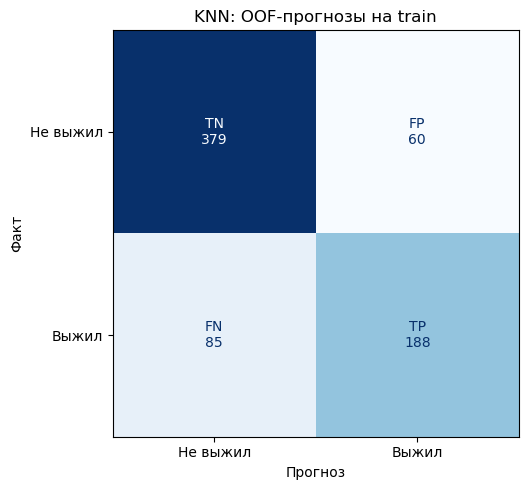

In [20]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ("preprocessor", make_preprocessor(scale=True)),
    ("model", KNeighborsClassifier(n_neighbors=5, weights="uniform")),
])

cv_predictions["KNN"] = cross_val_predict(
    knn_model, X_train, y_train, cv=cv
)
cv_scores["KNN"] = classification_metrics(
    y_train, cv_predictions["KNN"]
)

knn_model.fit(X_train, y_train)
models["KNN"] = knn_model

print("F1 на train:", round(f1_score(y_train, knn_model.predict(X_train)), 3))
print("F1 OOF:", round(cv_scores["KNN"]["F1"], 3))
display(pd.DataFrame.from_dict(cv_scores, orient="index").round(3))

disp = ConfusionMatrixDisplay.from_predictions(
    y_train, cv_predictions["KNN"],
    labels=[0, 1], display_labels=["Не выжил", "Выжил"],
    cmap="Blues", colorbar=False,
)
for name, text in zip(["TN", "FP", "FN", "TP"], disp.text_.ravel()):
    text.set_text(f"{name}\n{text.get_text()}")

disp.ax_.set(
    xlabel="Прогноз", ylabel="Факт",
    title="KNN: OOF-прогнозы на train",
)
plt.tight_layout()
plt.show()

KNN с пятью соседями получил OOF F1 = 0.722 при F1 на train = 0.807. Это самый низкий F1 среди пяти обученных моделей в данном сравнении. Лидером по OOF F1 остаётся Gradient Boosting (0.761). Все обязательные модели обучены; test пока не использовался.

## 21. Финальная оценка на локальном test

Выбираем модель по OOF F1 до просмотра test. Оцениваем все модели на одном test и сохраняем прогнозы; после этого параметры не меняем. Локальная проверка не заменяет оценку на единой выборке преподавателя.

Модель выбрана по OOF F1: Gradient Boosting


,Accuracy,Precision,Recall,F1,F1 > 0.70
Dummy,0.615,0.000,0.000,0.000,False
Decision Tree,0.771,0.759,0.594,0.667,False
Random Forest,0.782,0.759,0.638,0.693,False
Gradient Boosting,0.799,0.800,0.638,0.710,True
SVM,0.821,0.814,0.696,0.750,True
KNN,0.799,0.754,0.710,0.731,True


,Train F1,OOF F1,Test F1
Dummy,0.000,0.000,0.000
Decision Tree,0.822,0.737,0.667
Random Forest,0.875,0.751,0.693
Gradient Boosting,0.877,0.761,0.710
SVM,0.787,0.739,0.750
KNN,0.807,0.722,0.731


Test F1 выбранной модели: 0.71


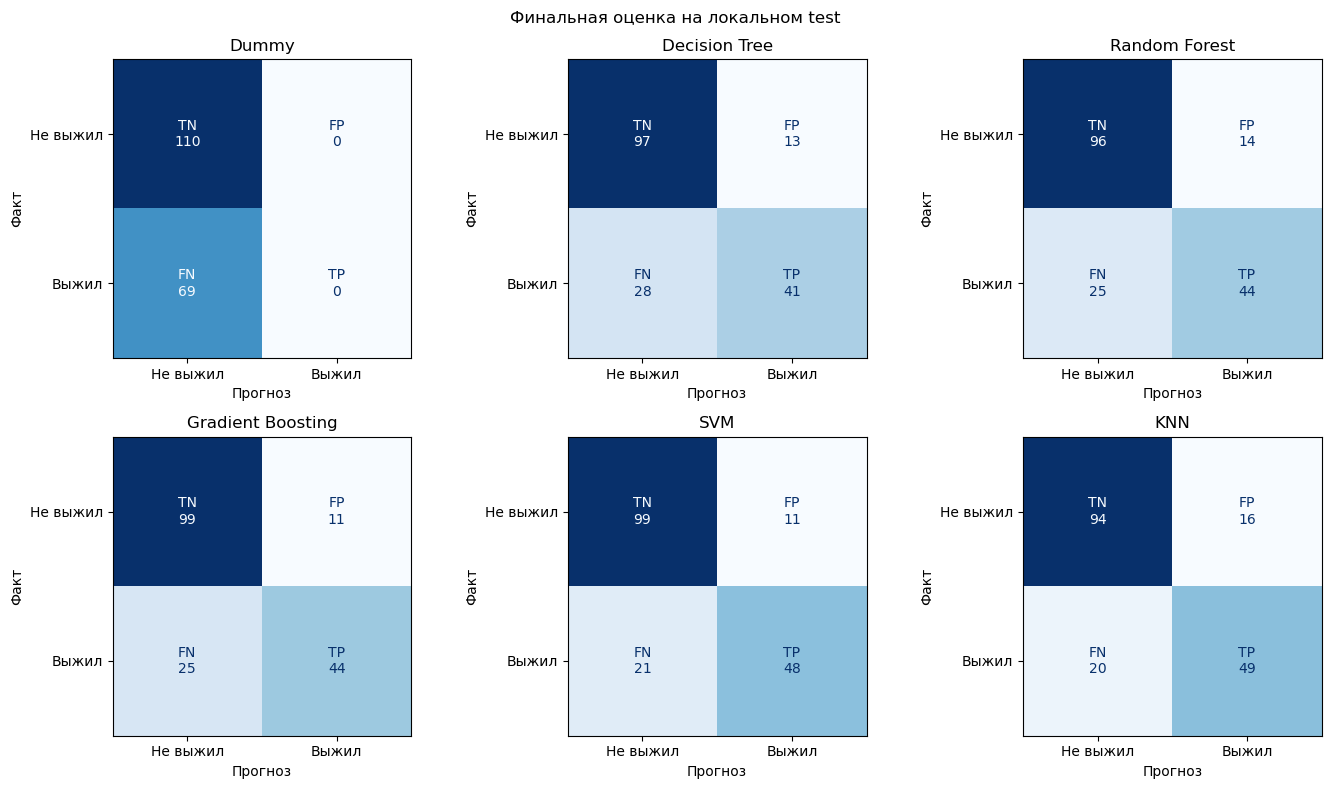

In [21]:
best_name = max(models, key=lambda name: cv_scores[name]["F1"])
best_model = models[best_name]
print("Модель выбрана по OOF F1:", best_name)

baseline.fit(X_train, y_train)
evaluation_models = {"Dummy": baseline, **models}
test_predictions = {}
test_scores = {}

for name, model in evaluation_models.items():
    test_predictions[name] = model.predict(X_test)
    test_scores[name] = classification_metrics(
        y_test, test_predictions[name]
    )

test_table = pd.DataFrame.from_dict(test_scores, orient="index")
test_table["F1 > 0.70"] = test_table["F1"] > 0.70
display(test_table.round(3))

f1_comparison = pd.DataFrame({
    "Train F1": {
        name: f1_score(y_train, model.predict(X_train), zero_division=0)
        for name, model in evaluation_models.items()
    },
    "OOF F1": {name: cv_scores[name]["F1"] for name in evaluation_models},
    "Test F1": test_table["F1"],
})
display(f1_comparison.round(3))
print("Test F1 выбранной модели:", round(test_scores[best_name]["F1"], 3))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for (name, predictions), ax in zip(test_predictions.items(), axes.ravel()):
    disp = ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1],
        display_labels=["Не выжил", "Выжил"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    for code, text in zip(["TN", "FP", "FN", "TP"], disp.text_.ravel()):
        text.set_text(f"{code}\n{text.get_text()}")
    ax.set(title=name, xlabel="Прогноз", ylabel="Факт")

plt.suptitle("Финальная оценка на локальном test")
plt.tight_layout()
plt.show()

До просмотра test по OOF F1 выбран Gradient Boosting. На локальном test его F1 = 0.710: порог 0.70 превышен. Также порог превысили SVM (0.750) и KNN (0.731); дерево и лес — нет. У дерева F1 на train = 0.822, на test = 0.667: разрыв сохраняется. Хотя максимальный тестовый F1 получил SVM, выбор модели по CV после просмотра test не пересматриваем. Дальше анализируем ошибки зафиксированного бустинга без изменения параметров.

## 22. Анализ ошибок по группам пассажиров

Используем сохранённые тестовые прогнозы выбранного бустинга. FP — погибшие, предсказанные как выжившие; FN — выжившие, предсказанные как погибшие. Сравниваем доли ошибок с учётом размеров групп.

In [22]:
error_analysis = X_test.assign(
    Actual=y_test,
    Predicted=test_predictions[best_name],
)
error_analysis["Error"] = error_analysis["Actual"] != error_analysis["Predicted"]
error_analysis["FP"] = (
    (error_analysis["Actual"] == 0) & (error_analysis["Predicted"] == 1)
)
error_analysis["FN"] = (
    (error_analysis["Actual"] == 1) & (error_analysis["Predicted"] == 0)
)

print("Модель:", best_name)
print(f"Ошибок: {error_analysis['Error'].sum()} из {len(error_analysis)}")
print("FP:", error_analysis["FP"].sum(), "| FN:", error_analysis["FN"].sum())

group_errors = error_analysis.groupby(["Sex", "Pclass"]).agg(
    n=("Error", "size"),
    errors=("Error", "sum"),
    FP=("FP", "sum"),
    FN=("FN", "sum"),
)
group_errors["Ошибки, %"] = (
    group_errors["errors"] / group_errors["n"] * 100
).round(2)

display(group_errors.sort_values("Ошибки, %", ascending=False))

Модель: Gradient Boosting
Ошибок: 36 из 179
FP: 11 | FN: 25


n  errors  FP  FN  Ошибки, %
Sex    Pclass                               
male   1       30      11   4   7      36.67
female 3       28      10   4   6      35.71
male   2       16       3   0   3      18.75
       3       72      10   1   9      13.89
female 1       15       1   1   0       6.67
       2       18       1   1   0       5.56

Бустинг допустил 36 ошибок: 25 FN и 11 FP. Чаще ошибочно предсказывал гибель выживших. На этом test наибольшая доля ошибок у мужчин первого класса (11 из 30, 36.67%) и женщин третьего класса (10 из 28, 35.71%). Размеры групп невелики, поэтому различия трактуем как описание данной выборки, а не устойчивое правило для всех пассажиров.

## 23. Примеры ошибок и проверка признаков

Показываем по два FP и FN с высокой уверенностью модели. `PassengerId` нужен только для поиска строки. Проверяем фактически используемые признаки и отсутствие пересечения строк train/test.

In [23]:
error_examples = error_analysis[error_analysis["Error"]].copy()
error_examples["P_survived"] = best_model.predict_proba(
    X_test.loc[error_examples.index]
)[:, 1]
error_examples["Type"] = np.where(error_examples["FP"], "FP", "FN")
error_examples["Confidence"] = np.where(
    error_examples["Predicted"] == 1,
    error_examples["P_survived"],
    1 - error_examples["P_survived"],
)

examples = (
    error_examples.sort_values(
        ["Type", "Confidence"], ascending=[True, False]
    ).groupby("Type", sort=False).head(2)
)
display(examples[[
    "PassengerId", "Sex", "Pclass", "Age", "Fare", "HasCabin",
    "Actual", "Predicted", "P_survived", "Type",
]].round(3))

used_features = [
    column
    for name, _, columns in best_model.named_steps["preprocessor"].transformers_
    if name != "remainder"
    for column in columns
]
excluded_columns = {"Survived", "PassengerId", "Name", "Ticket", "Cabin"}

print("Используемые признаки:", used_features)
print("Нежелательные столбцы среди используемых:",
      sorted(excluded_columns.intersection(used_features)))
print("Пересечение индексов train/test:",
      len(X_train.index.intersection(X_test.index)))

,PassengerId,Sex,Pclass,Age,Fare,HasCabin,Actual,Predicted,P_survived,Type
271,272,male,3,25.0,0.000,0,1,0,0.020,FN
804,805,male,3,27.0,6.975,0,1,0,0.020,FN
297,298,female,1,2.0,151.550,1,0,1,0.973,FP
199,200,female,2,24.0,13.000,0,0,1,0.868,FP


Используемые признаки: ['Age', 'SibSp', 'Parch', 'Fare', 'HasCabin', 'Pclass', 'Sex', 'Embarked']
Нежелательные столбцы среди используемых: []
Пересечение индексов train/test: 0


Возможная причина FN у пассажиров 272 и 805 — сочетание мужского пола, третьего класса и низкой стоимости билета: модель дала им вероятность выживания около 0.02. FP у пассажирок 298 и 200 могут отражать перенос общей высокой выживаемости женщин на отдельные исключения; у пассажирки 298 также первый класс и возраст 2 года. Это возможные интерпретации по EDA, а не доказанные причины конкретных прогнозов.

Модель использует восемь исходных/производных признаков. Целевая переменная, PassengerId, Name, Ticket и исходный Cabin в преобразования не входят. Пересечение индексов train/test равно 0; прямого использования цели или идентификаторов в проверенной схеме не обнаружено.

## 24. Итоговые выводы

- Сравнены Dummy, Decision Tree, Random Forest, Gradient Boosting, SVM и KNN на одинаковом стратифицированном разбиении. Предобработка обучалась внутри Pipeline; SVM и KNN использовали масштабирование.
- По OOF F1 до просмотра test выбран Gradient Boosting (0.761). На локальном test: Accuracy = 0.799, Precision = 0.800, Recall = 0.638, F1 = 0.710. Порог F1 > 0.70 превышен.
- Наибольший тестовый F1 получил SVM (0.750), затем KNN (0.731). Дерево (0.667) и лес (0.693) порог не превысили. Зафиксированный по CV выбор после просмотра test не меняли.
- Ограничение сложности уменьшило разрыв между train и OOF у дерева и леса. Качество зависит от настройки и разбиения; ансамбль не гарантирует превосходства над более простой моделью.
- Важнейшие признаки деревьев — пол, стоимость билета, возраст и класс. Наличие каюты тоже используется, но его независимая польза не доказана небольшой разницей OOF F1. Важность и корреляции не являются причинными эффектами.
- Бустинг допустил 36 ошибок: 25 FN и 11 FP. На этом test наибольшая доля ошибок у мужчин первого класса и женщин третьего. Цель и идентификаторы в признаки модели не входят.

**Ограничения:** test содержит только 179 пассажиров, а подгруппы ещё меньше. Оценки CV после подбора на тех же фолдах могут быть оптимистичными. Полученный F1 = 0.710 не гарантирует устойчивого превышения порога на новых данных. 